<h1> Policy Network

First, we build the policy network, examine the probability outputs, and then move on to the REINFORCE algorithm.

In this section, we move away from value-based methods and learn how a neural network can directly learn a policy for action selection.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import torch.nn as nn

from torch.distributions import Categorical


<h3> Step 1: Setting up the CartPole environment

In [3]:
# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Create environment
env = gym.make("CartPole-v1")

# Inspect spaces
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

# Reset environment
state, info = env.reset(seed=42)

print("Initial state:", state)
print("State shape:", state.shape)

# Extract dimensions
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

print("State dimension:", state_dim)
print("Action dimension:", action_dim)

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Initial state: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
State shape: (4,)
State dimension: 4
Action dimension: 2


<h3> Step 2: Building a Policy Network

In [4]:
class PolicyNetwork(nn.Module):

    def __init__(
        self,
        state_dim,
        action_dim,
        hidden_dim=128
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, state):
        return self.network(state)


policy_net = PolicyNetwork(
    state_dim=state_dim,
    action_dim=action_dim
)

print(policy_net)

PolicyNetwork(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


The output should represent an architecture consisting of three Linear layers and two ReLU layers; the final layer has two outputs.

Important note: We have intentionally omitted a Softmax layer at the end. Later, we will use `Categorical(logits=...)` to calculate the action distribution, which performs the conversion to probabilities in a numerically stable manner.

<h3> Step 3: Analyzing the network output

In [5]:
# Convert state to a PyTorch tensor
state_tensor = torch.as_tensor(
    state,
    dtype=torch.float32
).unsqueeze(0)

# Get logits and probabilities
with torch.no_grad():

    logits = policy_net(state_tensor)

    probabilities = torch.softmax(
        logits,
        dim=-1
    )

print("Logits:", logits)
print("Logits shape:", logits.shape)

print("Probabilities:", probabilities)
print("Probabilities shape:", probabilities.shape)

print(
    "Sum of probabilities:",
    probabilities.sum(dim=-1).item()
)

Logits: tensor([[ 0.0207, -0.0128]])
Logits shape: torch.Size([1, 2])
Probabilities: tensor([[0.5084, 0.4916]])
Probabilities shape: torch.Size([1, 2])
Sum of probabilities: 0.9999999403953552


The outputs are perfectly correct. The network has not yet been trained, so the probabilities for the two actions are nearly equal—exactly what we would expect given the initial weights.
- Logits: The network's raw output for the two actions.
- Probabilities: The probability for the left action is approximately 0.5084, and for the right action, it is about 0.4916.
- The sum of the probabilities is approximately 1.0. The very slight discrepancy is due to the precision of floating-point calculations.

<h3> Step 4: Action Sampling with Categorical

In DQN, we typically selected the action with the highest Q-value. In Policy Gradient, however, we sample the action from the policy's probability distribution.

In [8]:
# Convert state to tensor
state_tensor = torch.as_tensor(
    state,
    dtype=torch.float32
).unsqueeze(0)

# Get policy logits
logits = policy_net(state_tensor)

# Create action probability distribution
distribution = Categorical(
    logits=logits
)

# Sample an action
action = distribution.sample()

# Log-probability of the selected action
log_prob = distribution.log_prob(action)

print("Sampled action:", action.item())
print("Log probability:", log_prob.item())
print(
    "Probability of sampled action:",
    log_prob.exp().item()
)

Sampled action: 1
Log probability: -0.7100815176963806
Probability of sampled action: 0.49160411953926086


<h3> Step 5: Observing the stochastic behavior of policy

In [9]:
state_tensor = torch.as_tensor(
    state,
    dtype=torch.float32
).unsqueeze(0)

logits = policy_net(state_tensor)

distribution = Categorical(
    logits=logits
)

for i in range(10):
    action = distribution.sample()

    print(
        f"Sample {i + 1}: action = {action.item()}"
    )

Sample 1: action = 1
Sample 2: action = 0
Sample 3: action = 0
Sample 4: action = 1
Sample 5: action = 0
Sample 6: action = 0
Sample 7: action = 1
Sample 8: action = 1
Sample 9: action = 1
Sample 10: action = 1


Both actions 0 and 1 have been sampled, which indicates that the network uses the policy's probability distribution to select an action, rather than always choosing the action with the higher probability.

At this stage, we haven't learned anything yet; we have only implemented the mechanism for selecting actions.

<h3> Step 6: Executing an Episode and Storing Experiences

In the REINFORCE algorithm, the agent executes an episode and then updates its policy based on the rewards it has received.

For each step, we store two main items:
- log_prob: The logarithm of the probability of the action selected by the policy.
- reward: The reward received from the environment after executing that action.

In the CartPole-v1 environment, each step yields a reward of +1; therefore, the total episode reward is equal to the number of steps the agent managed to keep the pole balanced.

In [10]:
def generate_episode(env, policy_net):

    log_probs = []
    rewards = []

    state, info = env.reset()
    terminated = False
    truncated = False

    while not (terminated or truncated):

        # Convert state to tensor
        state_tensor = torch.as_tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0)

        # Calculate policy logits
        logits = policy_net(state_tensor)

        # Create action distribution
        distribution = Categorical(
            logits=logits
        )

        # Sample action
        action = distribution.sample()

        # Store log-probability
        log_prob = distribution.log_prob(
            action
        )

        # Interact with environment
        next_state, reward, terminated, truncated, info = (
            env.step(action.item())
        )

        log_probs.append(log_prob.squeeze())
        rewards.append(reward)

        state = next_state

    return log_probs, rewards

<h3> Step 7: Trial execution and output review

In [11]:
log_probs, rewards = generate_episode(
    env,
    policy_net
)

print("Episode length:", len(rewards))
print("Total reward:", sum(rewards))
print("Number of log_probs:", len(log_probs))
print("First 5 rewards:", rewards[:5])

print("\nFirst 5 log probabilities:")

for log_prob in log_probs[:5]:
    print(log_prob.item())

Episode length: 32
Total reward: 32.0
Number of log_probs: 32
First 5 rewards: [1.0, 1.0, 1.0, 1.0, 1.0]

First 5 log probabilities:
-0.713506817817688
-0.6724814176559448
-0.6737012267112732
-0.6836594939231873
-0.6953386664390564


The next step is the calculation of returns—that is, determining the return at each step based on the sum of future rewards. This value serves as the basis for deciding which policy decisions to reinforce or weaken.

<h3> Step 8: Calculating the Returns

In REINFORCE, we do not consider only the immediate reward; rather, we calculate the sum of future rewards.
The return from time step $t$ onwards is defined as follows:

$G_t=\sum_{k=0}^{T-t-1}\gamma^k r_{t+k}$

Where:
- $G_t$: The return from the current time step to the end of the episode.
- $r_t$: The reward at the current time step.
- $\gamma$: The discount factor.
- $T$: The length of the episode.

The discount factor determines the importance assigned to future rewards.

We use the following value:

$\gamma=0.99$

For example, if the next three rewards are each equal to one, the return is:

$G_t=1+0.99+0.99^2=2.9701$

Therefore, the initial steps of an episode typically yield a higher return, as they encompass rewards from a greater number of subsequent steps.

In [12]:
def compute_returns(rewards, gamma=0.99):

    returns = []
    G = 0.0

    # Traverse rewards backward
    for reward in reversed(rewards):

        G = reward + gamma * G
        returns.append(G)

    # Restore chronological order
    returns.reverse()

    return returns

Why do we move from the end of an episode to the beginning?
Because we can use the following recursive relationship:

$G_t=r_t+\gamma G_{t+1}$

Consequently, there is no need to re-sum all future rewards for every single step.

<h4> Calculation and review of the output

In [13]:
gamma = 0.99

returns = compute_returns(
    rewards,
    gamma=gamma
)

print("Episode length:", len(rewards))
print("Returns length:", len(returns))

print("\nFirst 5 returns:")
print(returns[:5])

print("\nLast 5 returns:")
print(returns[-5:])

print("\nFirst return:", returns[0])
print("Last return:", returns[-1])

Episode length: 32
Returns length: 32

First 5 returns:
[27.501966404214627, 26.76966303456023, 26.02996266117195, 25.282790566840355, 24.528071279636723]

Last 5 returns:
[4.90099501, 3.9403989999999998, 2.9701, 1.99, 1.0]

First return: 27.501966404214627
Last return: 1.0


<h3> Step 9: Calculating Policy Loss and Updating the Network

Now we arrive at the core of the REINFORCE algorithm: using returns to update the weights of the policy network.
So far, we have run one episode and have two arrays:
- `log_probs`: the logarithms of the probabilities of the selected actions
- `returns`: the discounted return for each step

We now combine these to construct the loss and learn the policy using gradient descent.

By calculating the gradient and executing `optimizer.step()`, the network weights are updated to steer the policy toward selecting actions that have yielded higher returns.

In [14]:
# Convert log probabilities and returns to tensors
log_probs_tensor = torch.stack(log_probs)

returns_tensor = torch.tensor(
    returns,
    dtype=torch.float32
)

# Create optimizer
optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

# Save parameters before the update
weights_before = [
    param.detach().clone()
    for param in policy_net.parameters()
]

# Calculate REINFORCE loss
loss = -(
    log_probs_tensor * returns_tensor
).sum()

# Gradient descent
optimizer.zero_grad()
loss.backward()

# Update policy network
optimizer.step()

# Measure parameter changes
total_change = sum(
    (after.detach() - before).abs().sum().item()
    for before, after in zip(
        weights_before,
        policy_net.parameters()
    )
)

print("Log probabilities shape:", log_probs_tensor.shape)
print("Returns shape:", returns_tensor.shape)
print("Policy loss:", loss.item())
print("Total parameter change:", total_change)
print(
    "Weights updated:",
    total_change > 0
)

Log probabilities shape: torch.Size([32])
Returns shape: torch.Size([32])
Policy loss: 329.9591064453125
Total parameter change: 7.661924095824361
Weights updated: True


If the weights have changed, it means the network has effectively undergone a learning step.

However, a change in weights does not, by itself, imply improved performance. Since REINFORCE relies on a stochastic gradient estimate, the performance in a subsequent episode could turn out to be either better or worse.

At this stage, we use raw returns. Later, by examining variance and incorporating a baseline, we will learn how to make policy updates more stable.

<h3> Step 10: Complete Train on REINFORCE

Since we previously performed a trial update on the network, it is best to re-initialize the network from scratch for the main experiment, ensuring that the training results are not influenced by that prior test.

In [15]:
# Reset random seeds
np.random.seed(42)
torch.manual_seed(42)

# Initialize a fresh policy network
policy_net = PolicyNetwork(
    state_dim=state_dim,
    action_dim=action_dim
)

# Create a fresh optimizer
optimizer = torch.optim.Adam(
    policy_net.parameters(),
    lr=1e-3
)

# Seed the environment
env.reset(seed=42)

print("Policy network reset successfully.")
print("Optimizer initialized.")

Policy network reset successfully.
Optimizer initialized.


<h4> Train Loop

In [16]:
def train_reinforce(
    env,
    policy_net,
    optimizer,
    num_episodes=1000,
    gamma=0.99
):
    episode_rewards = []
    episode_losses = []

    for episode in range(1, num_episodes + 1):

        # Generate a complete episode
        log_probs, rewards = generate_episode(
            env,
            policy_net
        )

        # Calculate discounted returns
        returns = compute_returns(
            rewards,
            gamma
        )

        returns_tensor = torch.tensor(
            returns,
            dtype=torch.float32
        )

        log_probs_tensor = torch.stack(log_probs)

        # Calculate REINFORCE loss
        loss = -(
            log_probs_tensor * returns_tensor
        ).sum()

        # Update policy
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_reward = sum(rewards)

        episode_rewards.append(total_reward)
        episode_losses.append(loss.item())

        if episode % 50 == 0:
            mean_reward = np.mean(
                episode_rewards[-50:]
            )

            mean_loss = np.mean(
                episode_losses[-50:]
            )

            print(
                f"Episode {episode:4d} | "
                f"Mean reward (last 50): "
                f"{mean_reward:.2f} | "
                f"Mean loss (last 50): "
                f"{mean_loss:.2f}"
            )

    return episode_rewards, episode_losses

<h4> Run the Train

An important point is that standard REINFORCE uses the raw return, which may exhibit high variance. We can examine the effect of a baseline later.

In the REINFORCE algorithm, the purpose of a baseline is to reduce the variance of the gradient—thereby making training more stable—without altering the expected value of the policy gradient.

In [17]:
reinforce_rewards, reinforce_losses = train_reinforce(
    env=env,
    policy_net=policy_net,
    optimizer=optimizer,
    num_episodes=1000,
    gamma=0.99
)

Episode   50 | Mean reward (last 50): 35.00 | Mean loss (last 50): 471.57
Episode  100 | Mean reward (last 50): 42.98 | Mean loss (last 50): 650.79
Episode  150 | Mean reward (last 50): 68.24 | Mean loss (last 50): 1372.76
Episode  200 | Mean reward (last 50): 180.54 | Mean loss (last 50): 5834.62
Episode  250 | Mean reward (last 50): 233.56 | Mean loss (last 50): 8067.53
Episode  300 | Mean reward (last 50): 125.92 | Mean loss (last 50): 3017.93
Episode  350 | Mean reward (last 50): 153.80 | Mean loss (last 50): 3970.24
Episode  400 | Mean reward (last 50): 257.18 | Mean loss (last 50): 8322.48
Episode  450 | Mean reward (last 50): 220.76 | Mean loss (last 50): 7019.16
Episode  500 | Mean reward (last 50): 333.82 | Mean loss (last 50): 12232.04
Episode  550 | Mean reward (last 50): 308.82 | Mean loss (last 50): 10909.63
Episode  600 | Mean reward (last 50): 250.58 | Mean loss (last 50): 8071.18
Episode  650 | Mean reward (last 50): 253.90 | Mean loss (last 50): 7938.88
Episode  700 | 

The REINFORCE algorithm has indeed learned, but it still lacks the necessary stability. The most significant evidence for this is the spike in performance—reaching near the environment's upper limit—at episode 900, followed by a sharp drop by episode 1000.

#### A) Initial Learning: Episodes 1 to 200
The average reward has increased from 35.00 to 180.54. This is a positive sign: the policy has succeeded in increasing the probability of selecting appropriate actions and maintaining balance for longer periods.

##### B) Progress with Fluctuations: Episodes 200 to 850
Performance has fluctuated, improving and declining at various points; for instance, the average dropped from 333.82 at episode 500 to 250.58 at episode 600, before rising again to 324.36 at episode 700.</br>
This behavior is consistent with the nature of the REINFORCE algorithm. Since raw returns are used, the gradient estimate can exhibit high variance, and policy updates may occasionally lead to a drop in performance.

#### C) Performance Surge: Episode 900
The average over the last 50 episodes reached 497.92, indicating that the agent achieved near-optimal performance for the environment during this interval.</br>
This result demonstrates that the network possesses the capacity to learn an effective policy.

#### D) Sharp Decline: Episode 1000
The average over the final 50 episodes plummeted to 79.76. </br> Consequently, we cannot conclude that the policy achieved a high level of performance by the end of the training process.</br>
This decline is likely due to the volatility of the policy updates; however, to definitively identify the cause, one would need to examine the plots and the specific behavior of the episodes.

#### Why has the loss become so large?
The loss values ​​have increased from 471.57 at the beginning to 18,904.94 by episode 900. This does not necessarily mean that the training is getting worse.
Our loss function is defined as follows:

$L(\theta)=-\sum_{t=0}^{T-1}G_t\log\pi_\theta(a_t\mid s_t)$

As episodes become longer, the number of terms in this summation increases, and the returns ($G_t$) for the initial steps also tend to be larger; consequently, the loss value can grow significantly.</br>
Therefore, in the REINFORCE algorithm, we do not use the raw loss value alone as a metric for policy quality. Instead, our primary criteria are the evaluation rewards and the stability of performance over time.

<h3> Step 11: Charts

<h3> Step 11.1: Learning Curve Chart

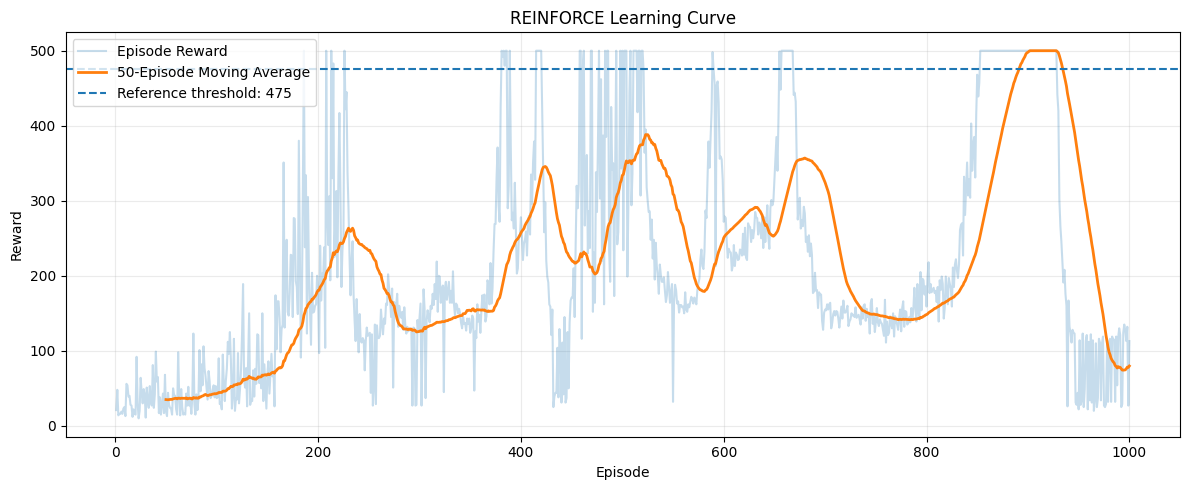

In [20]:
rewards = np.asarray(reinforce_rewards, dtype=float)
losses = np.asarray(reinforce_losses, dtype=float)

window = 50

moving_avg = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    np.arange(1, len(rewards) + 1),
    rewards,
    alpha=0.25,
    label="Episode Reward"
)

ax.plot(
    np.arange(window, len(rewards) + 1),
    moving_avg,
    linewidth=2,
    label="50-Episode Moving Average"
)

ax.axhline(
    475,
    linestyle="--",
    label="Reference threshold: 475"
)

ax.set_xlabel("Episode")
ax.set_ylabel("Reward")
ax.set_title("REINFORCE Learning Curve")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

<h3> Step 11.2: Loss Chart

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(losses, alpha=0.5, label="Episode Loss")

ax.set_xlabel("Episode")
ax.set_ylabel("Policy Loss")
ax.set_title("REINFORCE Policy Loss")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()